In [3]:
#read the parquet file
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import norm
from scipy.interpolate import PchipInterpolator
from pathlib import Path


Estimated correlation rho: 0.99
--- PRICING RESULTS (6 JANUARY 2020) ---
Basket Forward price (F_avg): 61.36 $
Global basket volatility (v): 0.2228
Theoretical Asian Call price at 78$: 1.1024 $
Exact Put strike for Zero-Cost Collar: 44.19 $
Verification - Call Price: 1.1024 $ | Put Price: 1.1025 $


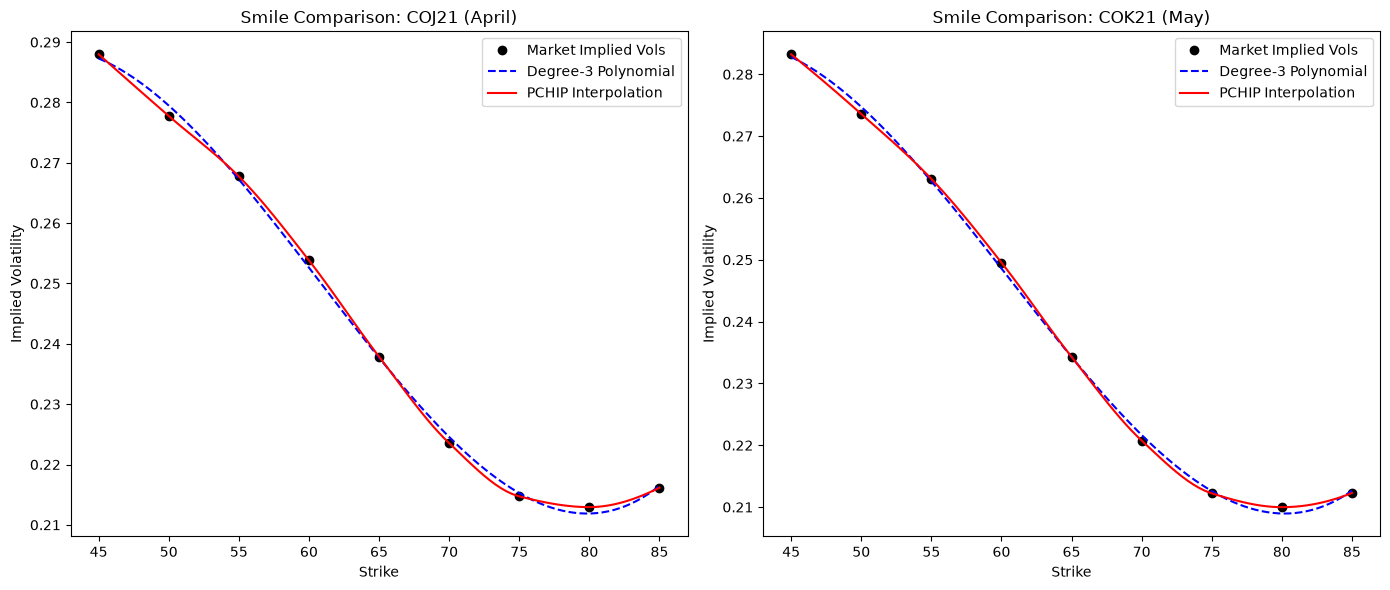

In [4]:

# =============================================================================
# PART 1: BASIC MATHEMATICAL FUNCTIONS
# =============================================================================

def Phi(x):
    """Cumulative distribution function of the standard normal distribution."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def black_76(F, K, sigma, t, T, option_type='call'):
    """Black-76 formula for pricing European Call or Put options (interest rate r = 0)."""
    d1 = (np.log(F / K) + 0.5 * sigma ** 2 * (T - t)) / (sigma * np.sqrt(T - t))
    d2 = d1 - sigma * np.sqrt(T - t)
    
    if option_type == 'call':
        return F * norm.cdf(d1) - K * norm.cdf(d2)
    elif option_type == 'put':
        return K * norm.cdf(-d2) - F * norm.cdf(-d1)
    else:
        raise ValueError("Invalid option type")

def vol_implicite(prix, F, K, T):
    """Extracts the implied volatility of an option using the bisection method."""
    bas, haut = 0.0001, 5.0
    for _ in range(100):  # Safety iteration limit to prevent infinite loops
        milieu = (bas + haut) / 2
        if black_76(F, K, milieu, 0, T, option_type='call') < prix:
            bas = milieu
        else:
            haut = milieu
        if haut - bas < 1e-6:
            break
    return (bas + haut) / 2

# =============================================================================
# PART 2: DATA LOADING AND DYNAMIC CORRELATION ESTIMATION
# =============================================================================

# 1. Load the clean parquet dataset


path = Path.cwd() / 'unpivoted_bid_offer_train_clean.parquet'
df = pd.read_parquet(path)
df['date'] = pd.to_datetime(df['date'])

valuation_date = pd.Timestamp('2020-01-06')
d = df[df['date'] == valuation_date]

c = d[d['underlying_ticker'] == 'COJ21 Comdty']   # April 2021 futures contract
c_K = d[d['underlying_ticker'] == 'COK21 Comdty'] # May 2021 futures contract

f1 = c['underlying_settlement'].iloc[0]
f2 = c_K['underlying_settlement'].iloc[0]


# 2. Dynamic estimation of the correlation rho up to the valuation date
def estimate_rho(data, recalibration_date):
    """Computes the historical correlation of log-returns between April and May futures."""
    tickers = ["COJ21 Comdty", "COK21 Comdty"]
    
    prices = (
        data.loc[data["date"] <= recalibration_date]
        [['date', 'underlying_ticker', 'underlying_settlement']]
        .drop_duplicates(subset=["date", "underlying_ticker"])
        .pivot(index="date", columns="underlying_ticker", values="underlying_settlement")
        .sort_index()
        [tickers]
        .dropna()
    )
    
    returns = np.log(prices / prices.shift(1)).dropna()
    
    # Fallback to a default high correlation if historical window is too short (e.g., initial valuation day)
    if len(returns) < 2:
        return 0.99  
        
    return returns["COJ21 Comdty"].corr(returns["COK21 Comdty"])

# Compute rho as of the valuation date
rho = estimate_rho(df, valuation_date)
print("Estimated correlation rho:", rho)
# =============================================================================
# PART 3: SMILE CALIBRATION (Polynomial vs PCHIP Interpolation)
# =============================================================================

# --- April contract (COJ21) smile extraction ---
strikes_1, vols_1 = [], []
for _, ligne in c.iterrows():
    if ligne['option_type'] == 'Call' and ligne['option_bid'] > 0:
        K = ligne['strike']
        prix = (ligne['option_bid'] + ligne['option_ask']) / 2
        F = ligne['underlying_settlement']
        T = ligne['time_to_expiry_days'] / 365
        strikes_1.append(K)
        vols_1.append(vol_implicite(prix, F, K, T))

coef_poly_1 = np.polyfit(strikes_1, vols_1, 3) # Degree-3 polynomial (for visual comparison)
smile_apr21 = PchipInterpolator(strikes_1, vols_1, extrapolate=True) # Robust PCHIP interpolator


# --- May contract (COK21) smile extraction ---
strikes_2, vols_2 = [], []
for _, ligne in c_K.iterrows():
    if ligne['option_type'] == 'Call' and ligne['option_bid'] > 0:
        K = ligne['strike']
        prix = (ligne['option_bid'] + ligne['option_ask']) / 2
        F = ligne['underlying_settlement']
        T = ligne['time_to_expiry_days'] / 365
        strikes_2.append(K)
        vols_2.append(vol_implicite(prix, F, K, T))

coef_poly_2 = np.polyfit(strikes_2, vols_2, 3)
smile_may21 = PchipInterpolator(strikes_2, vols_2, extrapolate=True)

# =============================================================================
# PART 4: ASIAN BASKET PRICING (MOMENT-MATCHING METHOD)
# =============================================================================

# 1. Time-to-fixing fractions (thetas) for each business day of February 2021
date_depart = valuation_date.date()
thetas = []
for jour in range(1, 29): 
    dt = date(2021, 2, jour)
    if dt.weekday() < 5:  # Business days only (Monday to Friday)
        thetas.append((dt - date_depart).days / 365.0)

n_total = len(thetas)  # Total 20 business days
n1 = 18                # 18 days allocated to April contract
n2 = n_total - n1      # 2 days allocated to May contract

theta_1 = thetas[:n1]  
theta_2 = thetas[n1:]  

# 2. Basket Forward price average (F_avg)
w1 = n1 / n_total
w2 = n2 / n_total
F_avg = w1 * f1 + w2 * f2

# 3. Strike projections (Sticky-Moneyness mapping)
K_call = 78.0
K1_call = f1 * (K_call / F_avg)
K2_call = f2 * (K_call / F_avg)

# 4. Read volatilities from PCHIP curves
sigma1 = float(smile_apr21(K1_call))
sigma2 = float(smile_may21(K2_call))

# 5. Moment-matching engine (Variances and Cross-Covariance)
def variance_totale(sigma1, sigma2, theta_1, theta_2, f1, f2, w1, w2, n1, n2):
    var_A1 = sum((2 * (n1 - k) + 1) * (math.exp(sigma1**2 * theta_1[k-1]) - 1) for k in range(1, n1 + 1))
    var_A1 *= (f1**2 / n1**2)

    var_A2 = sum((2 * (n2 - j) + 1) * (math.exp(sigma2**2 * theta_2[j-1]) - 1) for j in range(1, n2 + 1))
    var_A2 *= (f2**2 / n2**2)

    cov = sum(math.exp(rho * sigma1 * sigma2 * theta_1[k-1]) - 1 for k in range(1, n1 + 1))
    cov *= (f1 * f2 / n1)

    var_totale = (w1**2 * var_A1) + (w2**2 * var_A2) + (2 * w1 * w2 * cov)
    return var_totale

var_totale = variance_totale(sigma1, sigma2, theta_1, theta_2, f1, f2, w1, w2, n1, n2)
v = math.sqrt(math.log(1 + (var_totale / (F_avg**2))))

T_final = 1.0 
prix_call = black_76(F_avg, K_call, v, 0, T_final, option_type='call')

# =============================================================================
# PART 5: PUT STRIKE SEARCH (DICHOTOMY FOR ZERO-COST COLLAR)
# =============================================================================

bas = 40.0
haut = 78.0
prix_put = 0  

# Bisection loop to find K_put such that Put Price equals Call Price
for _ in range(100):
    K_put = (bas + haut) / 2
    K_put_1 = f1 * (K_put / F_avg)
    K_put_2 = f2 * (K_put / F_avg)
    
    sigma_put_1 = float(smile_apr21(K_put_1))
    sigma_put_2 = float(smile_may21(K_put_2))
    
    var_totale_put = variance_totale(sigma_put_1, sigma_put_2, theta_1, theta_2, f1, f2, w1, w2, n1, n2)
    v_put = math.sqrt(math.log(1 + (var_totale_put / (F_avg**2))))
    
    prix_put = black_76(F_avg, K_put, v_put, 0, T_final, option_type='put')
    
    if prix_put > prix_call:
        haut = K_put  # Put is too expensive -> lower the strike
    else:
        bas = K_put   # Put is too cheap -> raise the strike
        
    if abs(prix_put - prix_call) < 0.0001:
        break


# =============================================================================
# OUTPUTS AND COMPARATIVE PLOT (Polynomial vs PCHIP)
# =============================================================================
print("--- PRICING RESULTS (6 JANUARY 2020) ---")
print(f"Basket Forward price (F_avg): {F_avg:.2f} $")
print(f"Global basket volatility (v): {v:.4f}")
print(f"Theoretical Asian Call price at 78$: {prix_call:.4f} $")
print(f"Exact Put strike for Zero-Cost Collar: {K_put:.2f} $")
print(f"Verification - Call Price: {prix_call:.4f} $ | Put Price: {prix_put:.4f} $")

# Comparative plot: Polynomial degree 3 vs PCHIP
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
x_grid = np.linspace(min(strikes_1), max(strikes_1), 100)
plt.plot(strikes_1, vols_1, 'ko', label='Market Implied Vols')
plt.plot(x_grid, np.polyval(coef_poly_1, x_grid), 'b--', label='Degree-3 Polynomial')
plt.plot(x_grid, smile_apr21(x_grid), 'r-', label='PCHIP Interpolation')
plt.title('Smile Comparison: COJ21 (April)')
plt.xlabel('Strike')
plt.ylabel('Implied Volatility')
plt.legend()

plt.subplot(1, 2, 2)
x_grid_K = np.linspace(min(strikes_2), max(strikes_2), 100)
plt.plot(strikes_2, vols_2, 'ko', label='Market Implied Vols')
plt.plot(x_grid_K, np.polyval(coef_poly_2, x_grid_K), 'b--', label='Degree-3 Polynomial')
plt.plot(x_grid_K, smile_may21(x_grid_K), 'r-', label='PCHIP Interpolation')
plt.title('Smile Comparison: COK21 (May)')
plt.xlabel('Strike')
plt.ylabel('Implied Volatility')
plt.legend()

plt.tight_layout()
plt.show()